In [17]:
# ---------------------------------------------------------
# BIBLIOTHEKEN UND MODELLPARAMETER
# ---------------------------------------------------------

from matplotlib import pyplot as plt
from optimizer import Optimizer

plt.rcParams["figure.figsize"] = (14, 4)

# Allgemeine Modellparameter
DATA_FOLDER = "data_test"
N = 96                    # 96 Zeitschritte à 15 Minuten
DT = 0.25                 # Stunden pro Zeitschritt
PROSUMER = 0
T_EXAMPLE = 40

# Statischer Aufteilungsschlüssel
ALLOCATION_KEYS = {
    1: 0.5,
    2: 0.3,
    3: 0.2
}

# Zentrale Preisparameter [€/kWh]
PRICES = {
    "grid": 0.35,        # Haushaltsstrompreis [€/kWh]
    "p2p": 0.13,         # Vergütung Prosumer [€/kWh]
    "sharing": 0.13,     # Endpreis Consumer für Sharing [€/kWh]
    "feed_in": 0.08,     # Einspeisevergütung ohne ES [€/kWh]
    "residual": 0.00     # Vergütung Restüberschuss mit ES [€/kWh]
}

assert abs(sum(ALLOCATION_KEYS.values()) - 1.0) < 1e-9

print("=== Modellparameter ===")
for name, price in PRICES.items():
    print(f"{name:<12}: {price:.3f} €/kWh")

print(f"\nProsumer:          User {PROSUMER}")
print(f"Aufteilung:        {ALLOCATION_KEYS}")
print(f"Zeitschritte:      {N}")
print(f"Betrachtungsdauer: {N * DT:.0f} h")

=== Modellparameter ===
grid        : 0.350 €/kWh
p2p         : 0.130 €/kWh
sharing     : 0.130 €/kWh
feed_in     : 0.080 €/kWh
residual    : 0.000 €/kWh

Prosumer:          User 0
Aufteilung:        {1: 0.5, 2: 0.3, 3: 0.2}
Zeitschritte:      96
Betrachtungsdauer: 24 h


In [18]:
# ---------------------------------------------------------
# DATEN LADEN UND OPTIMIERER ERSTELLEN
# ---------------------------------------------------------

opt = Optimizer.from_folder2(DATA_FOLDER)

print("=== Eingangsdaten ===")
print(f"Preisprofile [€/kWh]:       {opt.price.shape}")
print(f"Verbrauchsprofile [kWh]:    {opt.cons.shape}")
print(f"Solarprofile [kWh]:         {opt.sun.shape}")
print(f"PV-Leistungen [kWh]:        {opt.pv}")
print(f"Batteriekapazitäten [kWh]:  {opt.battery}")

assert opt.cons.shape[1] >= N
assert opt.sun.shape[1] >= N
assert len(opt.pv) == opt.cons.shape[0]

print("\nDaten erfolgreich geladen.")

=== Eingangsdaten ===
Preisprofile [€/kWh]:       (4, 96)
Verbrauchsprofile [kWh]:    (4, 96)
Solarprofile [kWh]:         (4, 96)
PV-Leistungen [kWh]:        [5. 0. 0. 0.]
Batteriekapazitäten [kWh]:  [0. 0. 0. 0.]

Daten erfolgreich geladen.


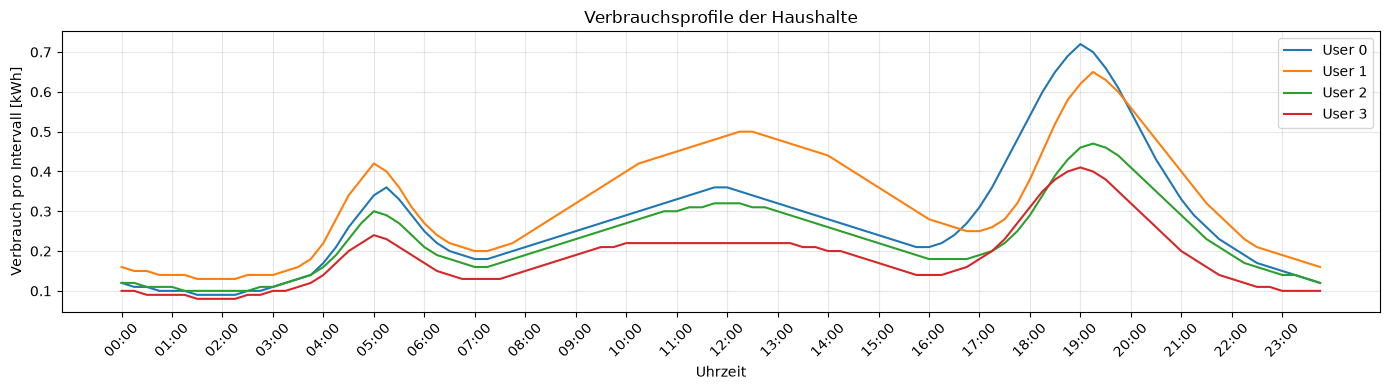

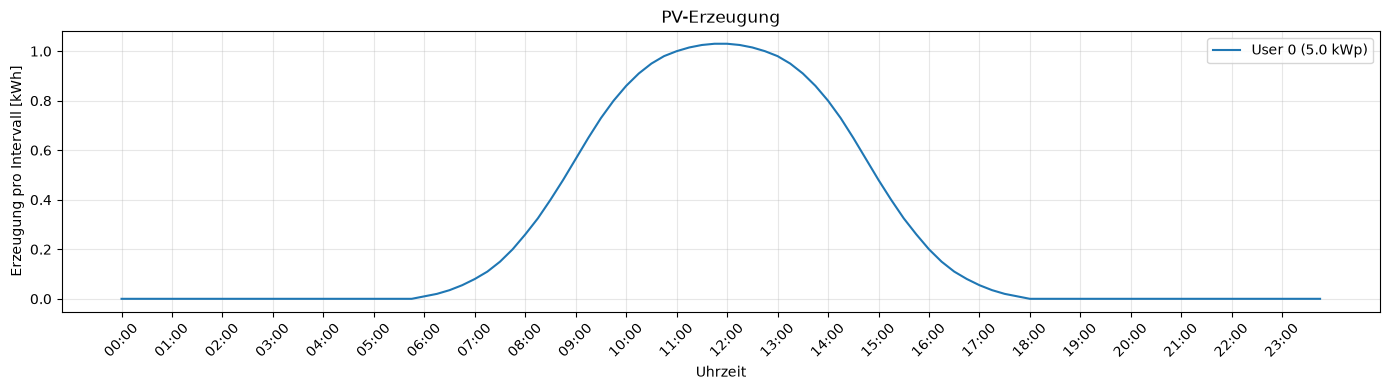

In [4]:
# ---------------------------------------------------------
# VERBRAUCHS- UND ERZEUGUNGSPROFILE PLOTTEN
# ---------------------------------------------------------

# Zeitachse: 4 Zeitschritte pro Stunde
ticks = range(0, N, 4)
labels = [f"{t // 4:02d}:00" for t in ticks]

# Verbrauchsprofile
plt.figure()

for user in range(opt.cons.shape[0]):
    plt.plot(
        range(N),
        opt.cons[user, :N],
        label=f"User {user}"
    )

plt.title("Verbrauchsprofile der Haushalte")
plt.xlabel("Uhrzeit")
plt.ylabel("Verbrauch pro Intervall [kWh]")
plt.xticks(ticks, labels, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# PV-Erzeugung
plt.figure()

for user in range(len(opt.pv)):
    if opt.pv[user] > 0:
        generation = opt.pv[user] * opt.sun[user, :N]

        plt.plot(
            range(N),
            generation,
            label=f"User {user} ({opt.pv[user]:.1f} kWp)"
        )

plt.title("PV-Erzeugung")
plt.xlabel("Uhrzeit")
plt.ylabel("Erzeugung pro Intervall [kWh]")
plt.xticks(ticks, labels, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# ---------------------------------------------------------
# ENERGY-SHARING-MODELL ERSTELLEN UND LÖSEN
# ---------------------------------------------------------

solver = opt.static_sharing_solver(
    allocation_keys=ALLOCATION_KEYS,
    prosumer=PROSUMER,
    p_p2p=PRICES["p2p"],
    p_feed_in=PRICES["feed_in"],
    residual_price=PRICES["residual"]
)

cost = solver.solve(N)

print("=== Energy-Sharing-Modell ===")
print("Berechnung abgeschlossen.")

=== Energy-Sharing-Modell ===
Berechnung abgeschlossen.


In [20]:
# ---------------------------------------------------------
# ENERGIEBILANZ DES PROSUMERS
# ---------------------------------------------------------

balance = solver.prosumer_energy_balance(N)

print("=== Energiebilanz Prosumer ===")

for key, values in balance.items():
    print(f"{key:<20}: {sum(values):8.3f} kWh")

# Prüfung der Energieerhaltung
generation_total = sum(balance["generation"])

energy_used = (
    sum(balance["shared"])
    + sum(balance["self_consumption"])
    + sum(balance["surplus"])
)

difference = generation_total - energy_used

print(f"\nBilanzdifferenz (sollte 0 sein): {difference:.8f} kWh")

assert abs(difference) < 1e-6, "Energiebilanz nicht erfüllt!"

# Vergleich mit Pyomo für alle Zeitschritte
max_import_error = max(
    abs(balance["grid_import"][t] - solver.model.el_in[PROSUMER, t].value)
    for t in range(N)
)

max_export_error = max(
    abs(balance["surplus"][t] - solver.model.el_out[PROSUMER, t].value)
    for t in range(N)
)

print(f"Max. Abweichung Netzbezug:    {max_import_error:.8f} kWh")
print(f"Max. Abweichung Netzeinspeisung: {max_export_error:.8f} kWh")

=== Energiebilanz Prosumer ===
generation          :   25.280 kWh
shared              :   24.850 kWh
self_consumption    :    0.430 kWh
grid_import         :   26.170 kWh
surplus             :    0.000 kWh

Bilanzdifferenz (sollte 0 sein): -0.00000000 kWh
Max. Abweichung Netzbezug:    0.00000000 kWh
Max. Abweichung Netzeinspeisung: 0.00000000 kWh


In [8]:
# ---------------------------------------------------------
# WIRTSCHAFTLICHE AUSWERTUNG
# ---------------------------------------------------------

# Prosumer: mit Energy Sharing
sharing = solver.prosumer_costs(
    N=N,
    grid_price=PRICES["grid"]
)

# Prosumer: ohne Energy Sharing
reference = solver.prosumer_reference_costs(
    N=N,
    grid_price=PRICES["grid"]
)

# Consumer: mit und ohne Energy Sharing
consumers = solver.consumer_costs(
    N=N,
    grid_price=PRICES["grid"],
    sharing_price=PRICES["sharing"]
)

print("=== Wirtschaftlicher Vergleich Prosumer ===")

print(f"{'':28s} {'Ohne ES':>12s} {'Mit ES':>12s}")
print("-" * 54)

print(
    f"{'Netzbezugskosten (€)':28s}"
    f"{reference['grid_cost']:12.3f}"
    f"{sharing['grid_cost']:12.3f}"
)

revenue_reference = reference["feed_in_revenue"]
revenue_sharing = (
    sharing["sharing_revenue"]
    + sharing["residual_revenue"]
)

print(
    f"{'Vermarktungserlöse (€)':28s}"
    f"{revenue_reference:12.3f}"
    f"{revenue_sharing:12.3f}"
)

print(
    f"{'Nettostromkosten (€)':28s}"
    f"{reference['net_cost']:12.3f}"
    f"{sharing['net_cost']:12.3f}"
)

prosumer_savings = reference["net_cost"] - sharing["net_cost"]

print("-" * 54)
print(f"Vorteil durch Energy Sharing: {prosumer_savings:.3f} €")

print("\n=== Wirtschaftlicher Vergleich Consumer ===")

print(
    f"{'Consumer':<12}"
    f"{'Ohne ES (€)':>14}"
    f"{'Mit ES (€)':>14}"
    f"{'Ersparnis (€)':>16}"
)

print("-" * 56)

total_consumer_savings = 0

for c, data in consumers.items():

    print(
        f"{c:<12}"
        f"{data['cost_without_es']:>14.3f}"
        f"{data['cost_with_es']:>14.3f}"
        f"{data['savings']:>16.3f}"
    )

    total_consumer_savings += data["savings"]

print("-" * 56)
print(f"Gesamtersparnis Consumer: {total_consumer_savings:.3f} €")

=== Wirtschaftlicher Vergleich Prosumer ===
                                  Ohne ES       Mit ES
------------------------------------------------------
Netzbezugskosten (€)               5.656       9.159
Vermarktungserlöse (€)             1.187       2.982
Nettostromkosten (€)               4.469       6.177
------------------------------------------------------
Vorteil durch Energy Sharing: -1.709 €

=== Wirtschaftlicher Vergleich Consumer ===
Consumer       Ohne ES (€)    Mit ES (€)   Ersparnis (€)
--------------------------------------------------------
1                   10.917         9.085           1.832
2                    7.714         6.576           1.138
3                    6.185         5.426           0.758
--------------------------------------------------------
Gesamtersparnis Consumer: 3.728 €


In [10]:
# ---------------------------------------------------------
# GESAMTBEWERTUNG DER ENERGIEGEMEINSCHAFT
# ---------------------------------------------------------

community_benefit = prosumer_savings + total_consumer_savings

print("=== Gesamtbewertung Energiegemeinschaft ===")

print(f"Vorteil Prosumer:       {prosumer_savings:8.3f} €")
print(f"Vorteil Consumer:       {total_consumer_savings:8.3f} €")

=== Gesamtbewertung Energiegemeinschaft ===
Vorteil Prosumer:         -1.709 €
Vorteil Consumer:          3.728 €


In [14]:
# ---------------------------------------------------------
# DETAILANALYSE EINES ZEITSCHRITTS
# ---------------------------------------------------------

t = T_EXAMPLE

print(f"=== Detailanalyse bei t={t} ({t * 15 // 60:02d}:{t * 15 % 60:02d} Uhr) ===")

print("\nProsumer")
print(f"PV-Erzeugung zum Zeitpunkt t={t}:                                 {balance['generation'][t]:.3f} kWh")
print(f"Verbrauchsbedarf für t={t}:                                       {solver.consf(PROSUMER, t):.3f} kWh")
print(f"Erzeugungsmenge, die der Prosumer an die Community abgibt:        {balance['shared'][t]:.3f} kWh")
print(f"Eigenverbrauch:                                                   {balance['self_consumption'][t]:.3f} kWh")
print(f"Netzbezug Reststrom:                                              {balance['grid_import'][t]:.3f} kWh")
print(f"PV-Überschuss:                                                    {balance['surplus'][t]:.3f} kWh")

print("\nConsumer")

generation = balance["generation"][t]

for c, alpha in ALLOCATION_KEYS.items():

    allocation = alpha * generation
    demand = solver.consf(c, t)
    shared = solver.model.imported[c, t].value
    grid = solver.model.el_in[c, t].value

    print(
        f"Consumer {c}: "
        f"durch den Aufteilungssch. vordefinierte Zuteilung={allocation:.3f}, "
        f"Sharing={shared:.3f}, "
        f"Verbrauch={demand:.3f}, "
        f"Netzbezug Reststrom={grid:.3f} kWh"
    )

print("\n")

solver.print_community_surplus()

=== Detailanalyse bei t=40 (10:00 Uhr) ===

Prosumer
PV-Erzeugung zum Zeitpunkt t=40:                                 0.860 kWh
Verbrauchsbedarf für t=40:                                       0.290 kWh
Erzeugungsmenge, die der Prosumer an die Community abgibt:        0.830 kWh
Eigenverbrauch:                                                   0.030 kWh
Netzbezug Reststrom:                                              0.260 kWh
PV-Überschuss:                                                    0.000 kWh

Consumer
Consumer 1: durch den Aufteilungssch. vordefinierte Zuteilung=0.430, Sharing=0.400, Verbrauch=0.400, Netzbezug Reststrom=0.000 kWh
Consumer 2: durch den Aufteilungssch. vordefinierte Zuteilung=0.258, Sharing=0.258, Verbrauch=0.270, Netzbezug Reststrom=0.012 kWh
Consumer 3: durch den Aufteilungssch. vordefinierte Zuteilung=0.172, Sharing=0.172, Verbrauch=0.220, Netzbezug Reststrom=0.048 kWh


t=38: Consumer 1 -> 0.005 kWh Community-Überschuss (zugeteilt: 0.365 kWh, verbraucht: 0.

np.float64(0.4300000000000003)